# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

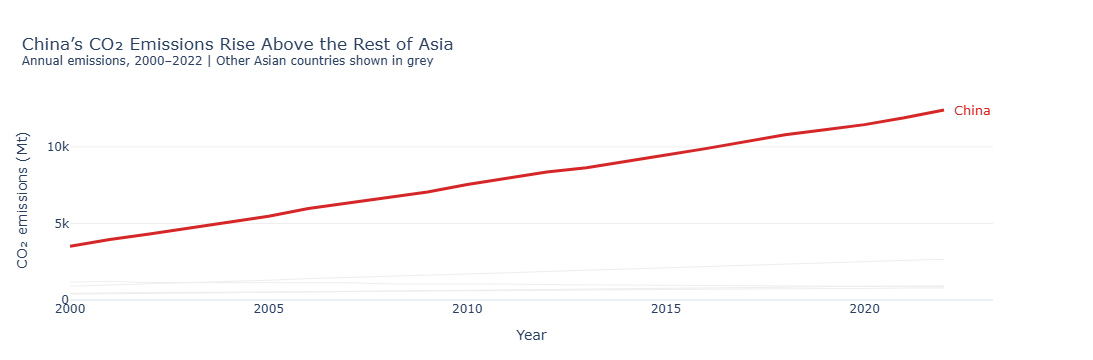

In [3]:
# Task — Multi-series line with highlight
# YOUR CODE HERE
import pandas as pd
import plotly.graph_objects as go

# Filter Asian countries
asia_df = df[
    df['Region'].str.contains('Asia', case=False, na=False)
].copy()

# Highlight China
highlight_country = 'China'

fig = go.Figure()

# Add all other Asian countries in thin grey lines
for country in asia_df['Country'].unique():
    if country == highlight_country:
        continue

    country_df = (
        asia_df[asia_df['Country'] == country]
        .sort_values('Year')
    )

    fig.add_trace(go.Scatter(
        x=country_df['Year'],
        y=country_df['CO2_Mt'],
        mode='lines',
        line=dict(color='#EEEEEE', width=1),
        showlegend=False,
        hovertemplate=(
            country + '<br>Year: %{x}'
            + '<br>CO₂: %{y:.1f} Mt<extra></extra>'
        )
    ))

# Add China as the highlighted line
china_df = (
    asia_df[asia_df['Country'] == highlight_country]
    .sort_values('Year')
)

if china_df.empty:
    raise ValueError(
        "China was not found in the Asian data. "
        "Check the Region and Country column values."
    )

fig.add_trace(go.Scatter(
    x=china_df['Year'],
    y=china_df['CO2_Mt'],
    mode='lines',
    line=dict(color='#D62728', width=3),
    name='China',
    showlegend=False,
    hovertemplate=(
        'China<br>Year: %{x}'
        + '<br>CO₂: %{y:.1f} Mt<extra></extra>'
    )
))

# Label China directly at the end of its line
last_point = china_df.iloc[-1]

fig.add_annotation(
    x=last_point['Year'],
    y=last_point['CO2_Mt'],
    text='China',
    showarrow=False,
    xanchor='left',
    xshift=8,
    font=dict(size=13, color='#D62728')
)

# Insight-led title
fig.update_layout(
    title=dict(
        text=(
            'China’s CO₂ Emissions Rise Above the Rest of Asia'
            '<br><sup>Annual emissions, 2000–2022 | Other Asian '
            'countries shown in grey</sup>'
        ),
        x=0.02,
        xanchor='left'
    ),
    xaxis_title='Year',
    yaxis_title='CO₂ emissions (Mt)',
    template='plotly_white',
    hovermode='x unified',
    margin=dict(l=70, r=100, t=100, b=60)
)

fig.update_xaxes(showgrid=False)
fig.update_yaxes(gridcolor='#EEEEEE', rangemode='tozero')

fig.show()
